<a href="https://colab.research.google.com/github/HamzaEric/aapl_volatility_modelling/blob/main/Notebooks/GARCH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Volatility Modelling Using GARCH

> The *average* daily return of a stock is tiny and famously
> unpredictable. So what *can* we forecast? **Risk itself** — how widely
> returns swing, and crucially, how that width *changes over time*.

### Clustering
Large moves follow large moves, calm
follows calm. The **GARCH** (Generalized Autoregressive Conditional
Heteroskedasticity) family is built precisely to capture that structure.


## Volatility: the standard deviation of returns

When analysts call a stock "volatile," they mean its returns spread widely
around their mean. Statistically, **volatility is the standard deviation
of returns**:

$$
\sigma = \sqrt{\frac{1}{N-1}\sum_{t=1}^{N}\left(r_t - \bar{r}\right)^2}
$$

where $r_t$ is the day-$t$ return, $\bar{r}$ the mean return, and $N$ the
number of observations.

>  Because daily returns sit roughly on a bell curve centred near zero,
> a *larger* standard deviation means *more extreme* daily gains and
> losses. The two synthetic series below — one calm, one wild — make the
> contrast concrete.

## Volatility clustering and squared returns

A defining feature of financial returns is that large moves (up or down)
**cluster** together — *volatility clustering*. Two views make it visible:

| View | What it shows | Why it helps |
|---|---|---|
| **Rolling standard deviation** | local volatility over a moving window | smooth picture of how risk drifts |
| **Squared returns** $r_t^2$ | magnitude with the sign removed | isolates "how big," ignoring direction |

>  Why *square* the returns? Returns $r_t$ are nearly uncorrelated over
> time — you can't predict tomorrow's direction. But their **magnitudes**
> are autocorrelated: a turbulent day makes the next day more likely to be
> turbulent. Squaring throws away the sign so this magnitude structure
> stands out. The same logic underpins ACF/PACF analysis next.

In [22]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 20.5 MB/s  0:00:00


In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from arch import arch_model


In [2]:
from yf_loader import get_daily_data

df_aapl = get_daily_data('AAPL')
df_nvda = get_daily_data('NVDA')

In [3]:
print(df_aapl.head())
print(df_nvda.head())

                open      high       low     close     volume
date                                                         
1980-12-12  0.098122  0.098549  0.098122  0.098122  469033600
1980-12-15  0.093430  0.093430  0.093003  0.093003  175884800
1980-12-16  0.086604  0.086604  0.086177  0.086177  105728000
1980-12-17  0.088310  0.088737  0.088310  0.088310   86441600
1980-12-18  0.090870  0.091297  0.090870  0.090870   73449600
                open      high       low     close      volume
date                                                          
1999-01-22  0.040018  0.044663  0.035492  0.037517  2714688000
1999-01-25  0.040494  0.041923  0.037517  0.041448   510480000
1999-01-26  0.041923  0.042757  0.037636  0.038231   343200000
1999-01-27  0.038350  0.039303  0.036206  0.038113   244368000
1999-01-28  0.038113  0.038350  0.037755  0.037993   227520000


## Explore Volatility


Before modelling, develop visual intuition for volatility in the AAPL returns, comparing with NVDA

In [5]:
def wrangle_returns(df: pd.DataFrame, n_observations: int = None) -> pd.Series:
    """Calculate daily percentage returns from a price DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        Market data containing a "close" column and DatetimeIndex.
    n_observations : int, optional
        Number of return observations to keep (most recent).
        Returns all history if None.

    Returns
    -------
    pd.Series
        Named "return", no NaN values, DatetimeIndex sorted ascending.
    """

    df.sort_index(ascending=True, inplace=True)


    returns = df["close"].pct_change() * 100
    returns.name = "return"


    returns.dropna(inplace=True)


    if n_observations:
        return returns.tail(n_observations)

    return returns


y_aapl = wrangle_returns(df_aapl, n_observations=2500)
y_nvda = wrangle_returns(df_nvda, n_observations=2500)

print("y_aapl type:", type(y_aapl))
print("y_aapl shape:", y_aapl.shape)
y_aapl.head()

y_aapl type: <class 'pandas.core.series.Series'>
y_aapl shape: (2500,)


,return
date,
2016-11-28,-0.196799
2016-11-29,-0.098605
2016-11-30,-0.843337
2016-12-01,-0.931957
2016-12-02,0.374454


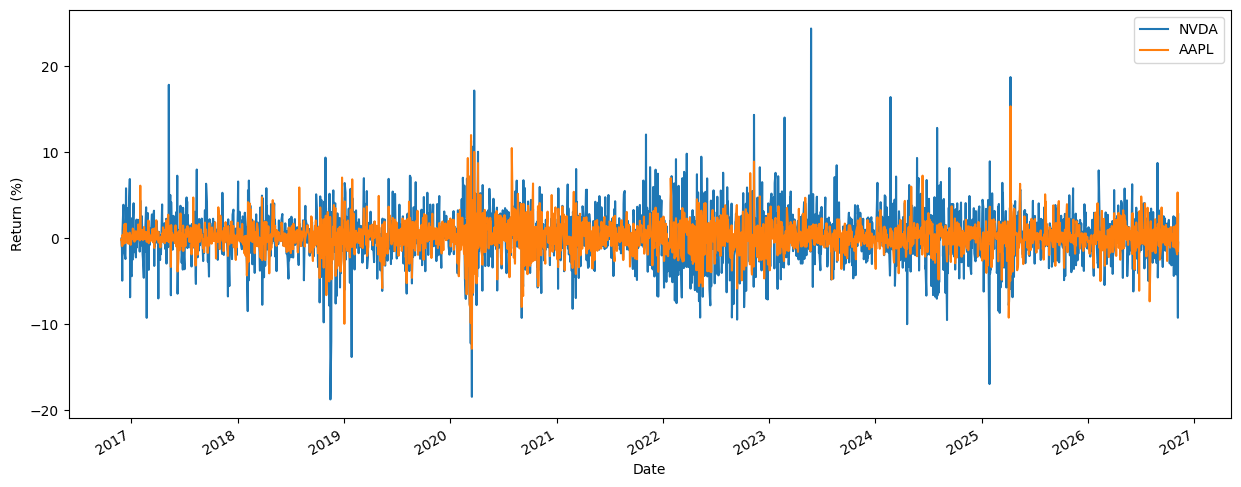

In [7]:
fig, ax = plt.subplots(figsize=(15, 6))
y_nvda.plot(ax=ax, label="NVDA")
y_aapl.plot(ax=ax, label="AAPL")

ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

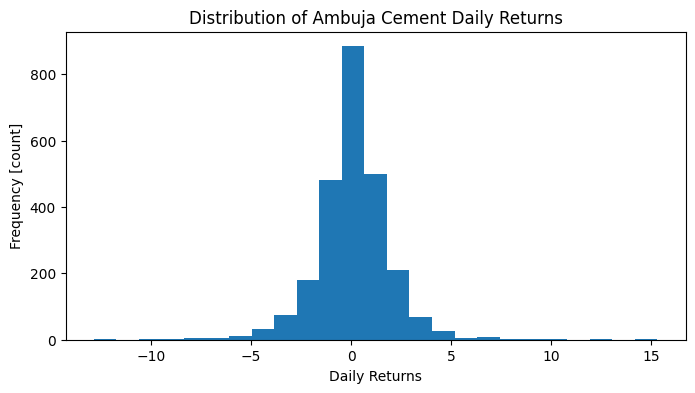

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_aapl, bins=25)
ax.set_xlabel("Daily Returns")
ax.set_ylabel("Frequency [count]")
ax.set_title("Distribution of Ambuja Cement Daily Returns")
plt.show()

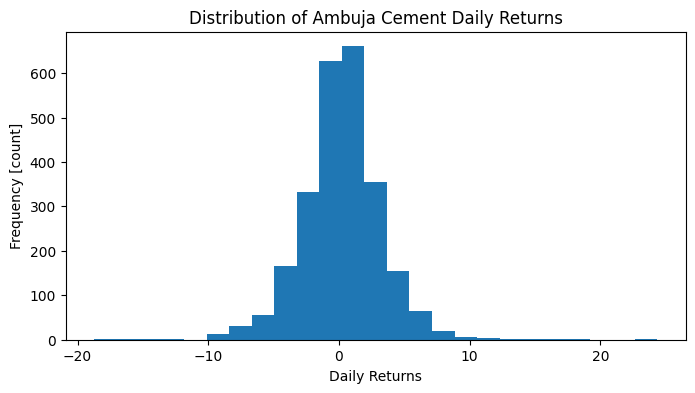

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_nvda, bins=25)
ax.set_xlabel("Daily Returns")
ax.set_ylabel("Frequency [count]")
ax.set_title("Distribution of Ambuja Cement Daily Returns")
plt.show()

> The distribution is centred near zero and roughly symmetric — but look
> at the **tails**: a few days sit far from the centre, more than a true
> normal curve would allow. Those *fat tails* are why a constant-variance
> Gaussian under-states risk, and another nudge toward GARCH.


# Volatility

In [13]:
aapl_daily_vol = y_aapl.std()
nvda_daily_vol = y_nvda.std()

# Calculate annual volatility (daily volatility * sqrt(252 trading days))
aapl_annual_vol = aapl_daily_vol * np.sqrt(252)
nvda_annual_vol = nvda_daily_vol * np.sqrt(252)

print("aapl  — daily:", round(aapl_daily_vol, 4),
      " | annual:", round(aapl_annual_vol, 4))
print("nvda  — daily:", round(nvda_daily_vol, 4),
      " | annual:", round(nvda_annual_vol, 4))

aapl  — daily: 1.8405  | annual: 29.2167
nvda  — daily: 3.1071  | annual: 49.3234


> Nvidia's daily *and* annual
> volatility exceed Apple's, and each annual value is its daily one times
> $\sqrt{252}$.

# 50-day rolling volatility

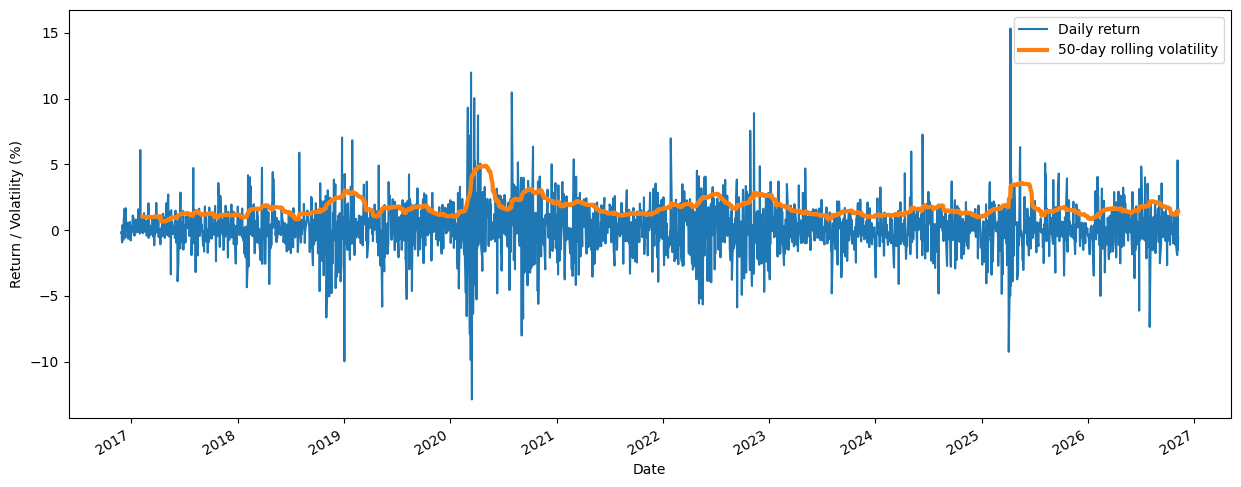

In [14]:
rolling_50d = y_aapl.rolling(window=50).std().dropna()

fig, ax = plt.subplots(figsize=(15, 6))
y_aapl.plot(ax=ax, label="Daily return")
rolling_50d.plot(
    ax=ax, label="50-day rolling volatility",
    linewidth=3
)
ax.set_xlabel("Date")
ax.set_ylabel("Return / Volatility (%)")
ax.legend()
plt.show()

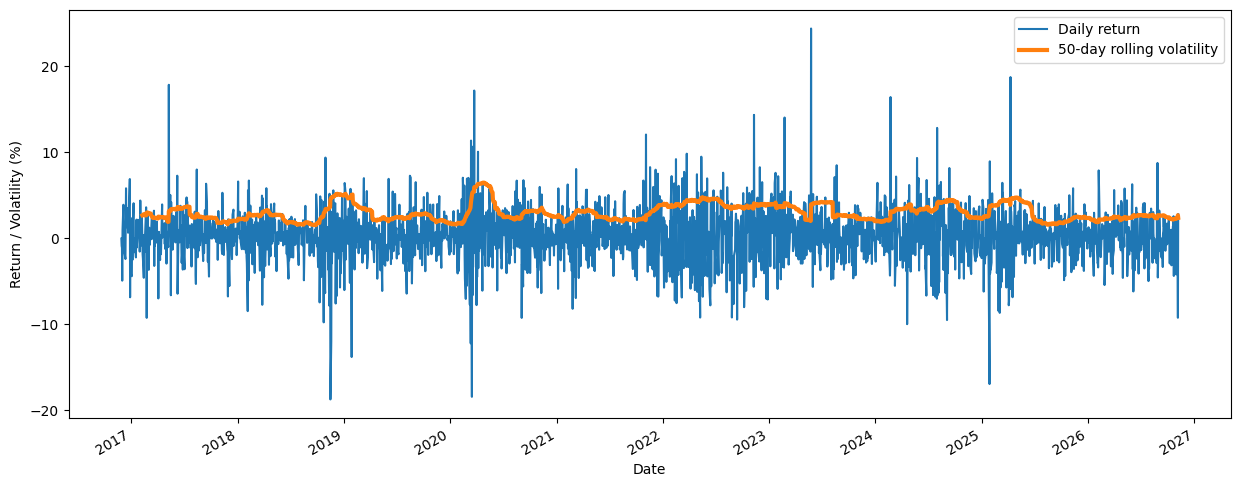

In [15]:
rolling_50d = y_nvda.rolling(window=50).std().dropna()

fig, ax = plt.subplots(figsize=(15, 6))
y_nvda.plot(ax=ax, label="Daily return")
rolling_50d.plot(
    ax=ax, label="50-day rolling volatility",
    linewidth=3
)
ax.set_xlabel("Date")
ax.set_ylabel("Return / Volatility (%)")
ax.legend()
plt.show()

>  The thick rolling line is a **direct picture of time-varying
> volatility**: where it climbs, returns are swinging widely; where it
> dips, the market is calm. A constant-variance model would replace this
> whole wandering curve with one flat level — visibly wrong.

# Squared Returns

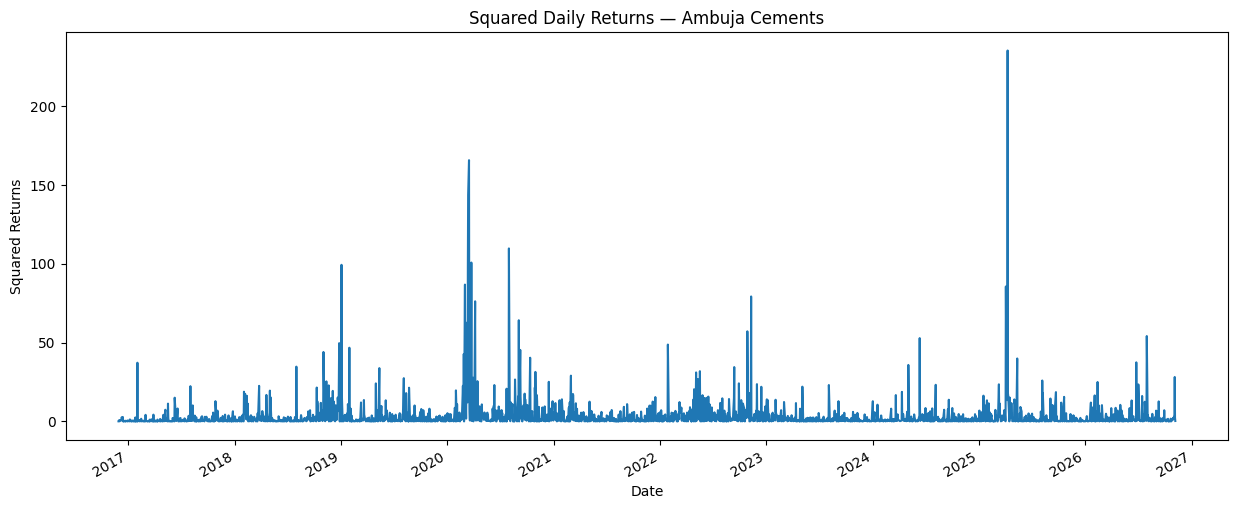

In [16]:
fig, ax = plt.subplots(figsize=(15, 6))
(y_aapl ** 2).plot(ax=ax)
ax.set_xlabel("Date")
ax.set_ylabel("Squared Returns")
ax.set_title("Squared Daily Returns — Ambuja Cements")
plt.show()

# ACF and PACF Plots

>  The tall spikes bunch together rather than scattering evenly — the
> signature of clustering, and the exact quantity (squared shocks) the ARCH
> term $\alpha\,\varepsilon_{t-1}^2$ feeds on.

Significant lags
reveal how many past observations influence current volatility, guiding the
choice of $p$ and $q$.

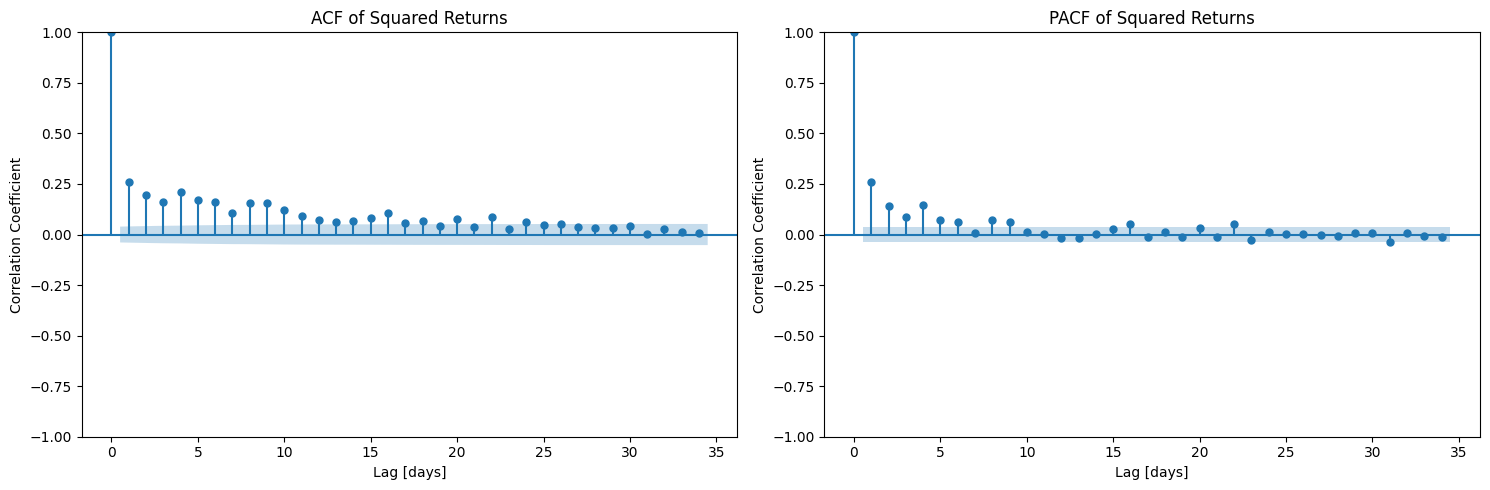

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(y_aapl ** 2, ax=axes[0])
axes[0].set_xlabel("Lag [days]")
axes[0].set_ylabel("Correlation Coefficient")
axes[0].set_title("ACF of Squared Returns")

plot_pacf(y_aapl ** 2, ax=axes[1])
axes[1].set_xlabel("Lag [days]")
axes[1].set_ylabel("Correlation Coefficient")
axes[1].set_title("PACF of Squared Returns")

plt.tight_layout()
plt.show()

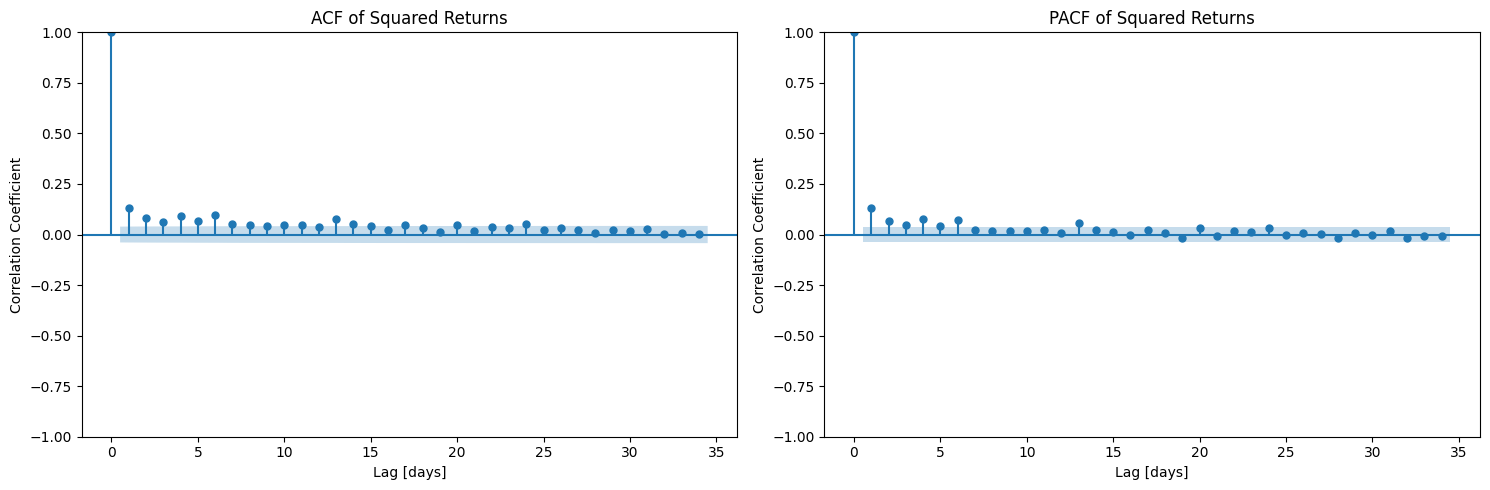

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(y_nvda ** 2, ax=axes[0])
axes[0].set_xlabel("Lag [days]")
axes[0].set_ylabel("Correlation Coefficient")
axes[0].set_title("ACF of Squared Returns")

plot_pacf(y_nvda ** 2, ax=axes[1])
axes[1].set_xlabel("Lag [days]")
axes[1].set_ylabel("Correlation Coefficient")
axes[1].set_title("PACF of Squared Returns")

plt.tight_layout()
plt.show()

## The GARCH model

**today's variance is a blend of recent shocks
and recent variance.** GARCH writes that sentence as a recursion.

Let $\varepsilon_t$ be the return shock on day $t$ (the return minus its
mean) and $\sigma_t^2$ the *conditional* variance — the variance given
everything known up to day $t-1$.

> 🧮 **ARCH(q)** — variance from past shocks only
>
> The Autoregressive Conditional Heteroskedasticity model says variance
> reacts to the last $q$ squared shocks:
>
> $$\sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i\, \varepsilon_{t-i}^2$$
>
> A big move yesterday ($\varepsilon_{t-1}^2$ large) inflates today's
> variance. The weakness: to capture *persistent* calm/storm regimes you
> need many lags.

> 🧮 **GARCH(p, q)** — add past variance for memory
>
> GARCH generalises ARCH by also feeding back the last $p$ variance
> estimates:
>
> $$\sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i\, \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j\, \sigma_{t-j}^2$$
>
> The $\beta$ terms give the model **long memory** with very few
> parameters — the whole reason GARCH usually beats a high-order ARCH.

> 🧮 **GARCH(1, 1)** — the workhorse
>
> One shock term and one variance term is enough for most equity series:
>
> $$\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2$$
>
> Read it as a recipe for tomorrow's variance: a baseline ($\omega$), plus
> a reaction to **yesterday's shock** ($\alpha$), plus a carry-over of
> **yesterday's variance** ($\beta$).

> 🧠 Two numbers that decode any fitted GARCH(1,1)
>
> - **Persistence** $\alpha + \beta$. The closer to 1, the longer a burst
>   of volatility lingers before fading. Stationarity requires
>   $\alpha + \beta < 1$.
> - **Long-run (unconditional) variance** — the level volatility reverts
>   to:
>
> $$\sigma^2_{\text{long-run}} = \frac{\omega}{1 - \alpha - \beta}$$
>
> A persistence of, say, 0.95 means shocks decay slowly and forecasts
> drift back to this level only gradually.

The `arch` library fits all of this in one call:

In [20]:
cutoff = int(len(y_aapl) * 0.8)
y_train = y_aapl.iloc[:cutoff]

print("y_train length:", len(y_train))
print("y_train date range:",
      y_train.index[0].date(), "to",
      y_train.index[-1].date())

y_train length: 2000
y_train date range: 2016-11-28 to 2024-11-07


In [24]:
# Instantiate and fit the GARCH(1,1) model
model = arch_model(y_train, p=1, q=1, rescale=False).fit(disp="off")

print("model type:", type(model))
print(f"AIC: {model.aic:.2f}  |  BIC: {model.bic:.2f}")
model.summary()

model type: <class 'arch.univariate.base.ARCHModelResult'>
AIC: 7690.49  |  BIC: 7712.89


<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                 return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3841.24
Distribution:                  Normal   AIC:                           7690.49
Method:            Maximum Likelihood   BIC:                           7712.89
                                        No. Observations:                 2000
Date:                Sun, Nov 08 2026   Df Residuals:                     1999
Time:                        01:56:59   Df Model:                            1
                               Mean Model                               
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.1877  3.690e-02      5.087  3.646e-07 [  0.115,  0.260]
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1239  5.539e-02      2.236  2.533e-02 [1.531e-02,  0.232]
alpha[1]       0.0966  2.887e-02      3.346  8.196e-04 [4.002e-02,  0.153]
beta[1]        0.8656  4.010e-02     21.586 2.455e-103   [  0.787,  0.944]
==========================================================================

Covariance estimator: robust
"""

> Reading the summary against the theory
>
> - `omega`, `alpha[1]`, `beta[1]` are the $\omega$, $\alpha$, $\beta$ of
>   the GARCH(1,1) equation. Small p-values (≈ 0) mean each term is
>   statistically real.
> - Add `alpha[1] + beta[1]` to get the **persistence**. For equities it
>   typically lands near 0.9–0.99, confirming that volatility shocks fade
>   slowly — precisely the behaviour the rolling plot showed.
> - **AIC/BIC** are only meaningful *relative* to another fit; keep them to
>   compare against alternative $p, q$.

# **Training returns with the $\pm 2$ standard-deviation conditional-volatility envelope**


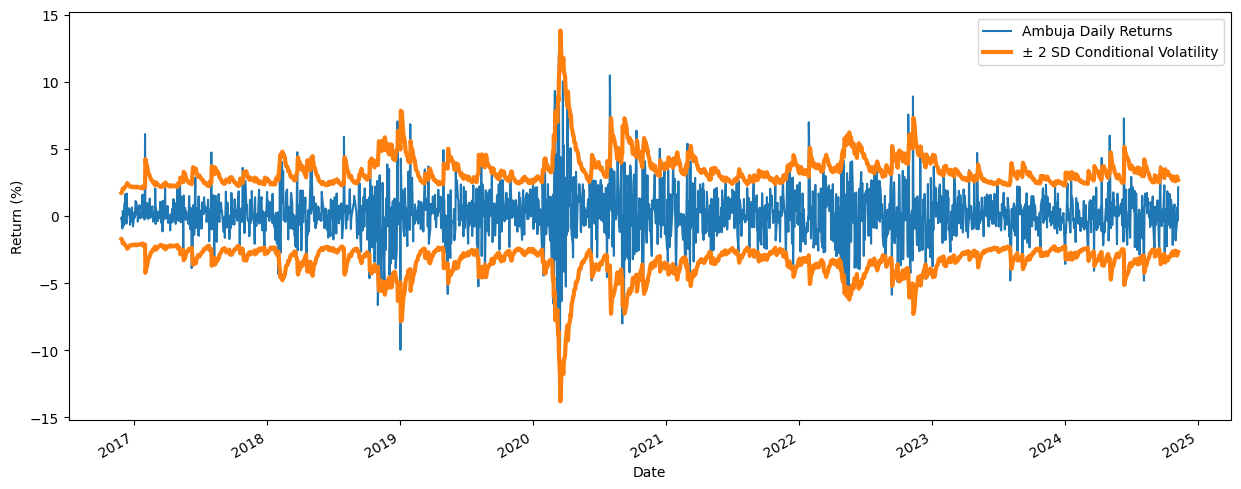

In [25]:
fig, ax = plt.subplots(figsize=(15, 6))

# Plot training returns
y_train.plot(ax=ax, label="Ambuja Daily Returns")

# Plot +2 SD conditional volatility
(2 * model.conditional_volatility).plot(
    ax=ax, color="C1",
    label="± 2 SD Conditional Volatility",
    linewidth=3
)

# Plot -2 SD conditional volatility (no extra legend entry)
(-2 * model.conditional_volatility.rename("")).plot(
    ax=ax, color="C1", linewidth=3
)

ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

> The orange envelope is the model's *fitted* $\pm 2\sigma_t$. It should
> hug the returns — breathing wider exactly where the return spikes
> cluster, tighter where they calm. Roughly 95% of returns falling inside
> it is the visual sign the conditional variance is well-calibrated.

# Standard Residuals

Standard residuals (or standardized residuals) are the raw errors of a statistical model divided by their estimated standard deviation

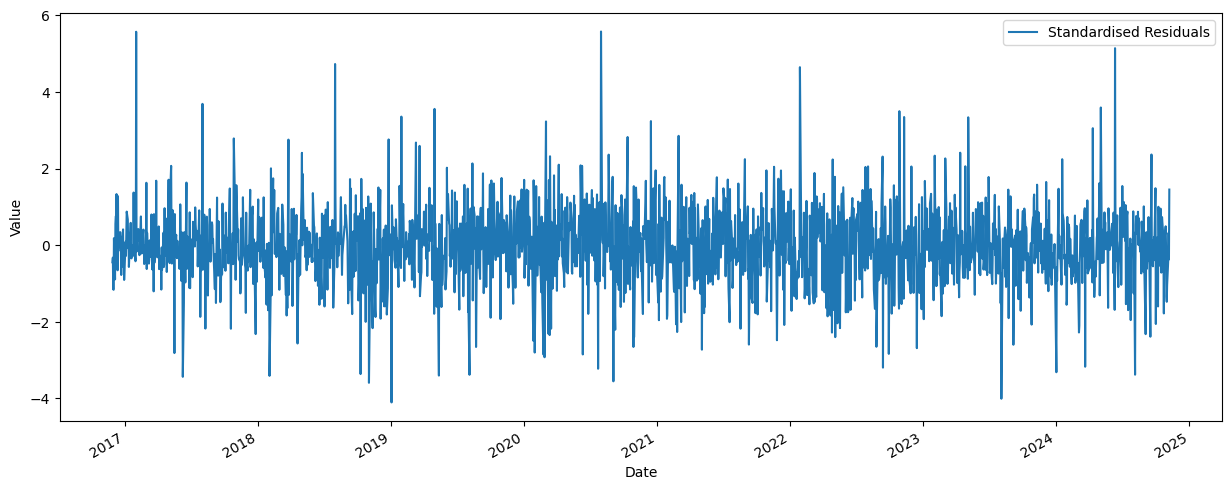

In [26]:
fig, ax = plt.subplots(figsize=(15, 6))
model.std_resid.plot(ax=ax, label="Standardised Residuals")
ax.set_xlabel("Date")
ax.set_ylabel("Value")
ax.legend()
plt.show()

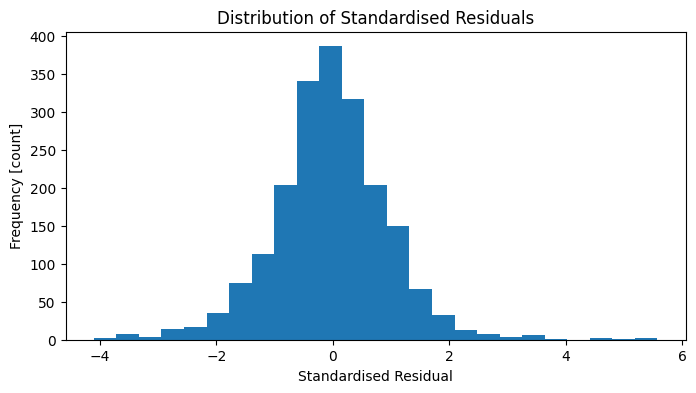

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(model.std_resid, bins=25)
ax.set_xlabel("Standardised Residual")
ax.set_ylabel("Frequency [count]")
ax.set_title("Distribution of Standardised Residuals")
plt.show()

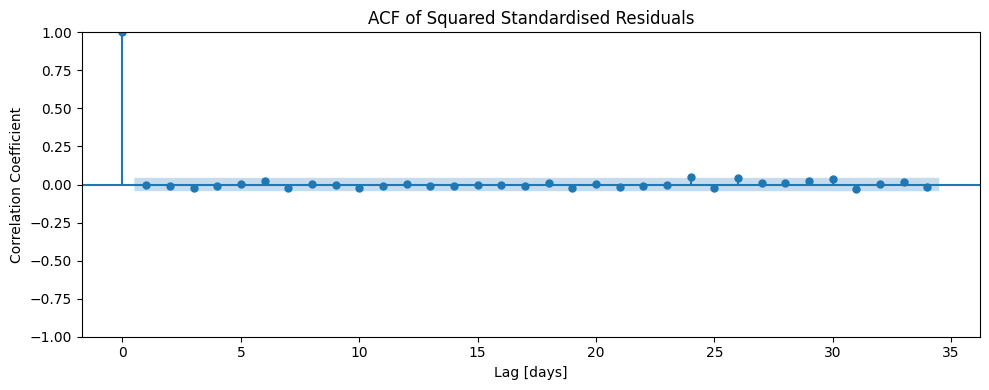

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(model.std_resid ** 2, ax=ax)
ax.set_xlabel("Lag [days]")
ax.set_ylabel("Correlation Coefficient")
ax.set_title(
    "ACF of Squared Standardised Residuals"
)
plt.tight_layout()
plt.show()

 If GARCH has
captured the volatility structure, no lag should sit significantly outside
the band.

> 📊 This is the decisive diagnostic. Compare it with the ACF of squared
> *raw* returns from Section 4, where early lags broke through the band.
> Here they should be **back inside** it — the leftover $z_t^2$ carry no
> structure, so the model extracted the clustering it was meant to.

# Walk-Forward Validation

Because the input is returns but the output is (latent) volatility, a
simple test-set RMSE against observed volatility is unavailable. Instead you
use **walk-forward validation**: repeatedly retrain on an expanding window,
forecast one step ahead, and overlay the predicted volatility on the actual
returns.

In [29]:
predictions = []
test_size = int(len(y_aapl) * 0.2)

for i in range(test_size):
    # Expanding training window
    y_wf_train = y_aapl.iloc[: -(test_size - i)]

    # Fit GARCH(1,1)
    wf_model = arch_model(
        y_wf_train, p=1, q=1, rescale=False
    ).fit(disp="off")

    # One-step-ahead volatility (sqrt of variance)
    next_vol = (
        wf_model.forecast(horizon=1, reindex=False)
        .variance.iloc[0, 0] ** 0.5
    )
    predictions.append(next_vol)

# Build Series from predictions
y_test_wfv = pd.Series(
    predictions,
    index=y_aapl.tail(test_size).index
)

print("y_test_wfv type:", type(y_test_wfv))
print("y_test_wfv shape:", y_test_wfv.shape)
y_test_wfv.head()

y_test_wfv type: <class 'pandas.core.series.Series'>
y_test_wfv shape: (500,)


,0
date,
2024-11-08,1.432755
2024-11-11,1.381538
2024-11-12,1.400758
2024-11-13,1.350784
2024-11-14,1.306293


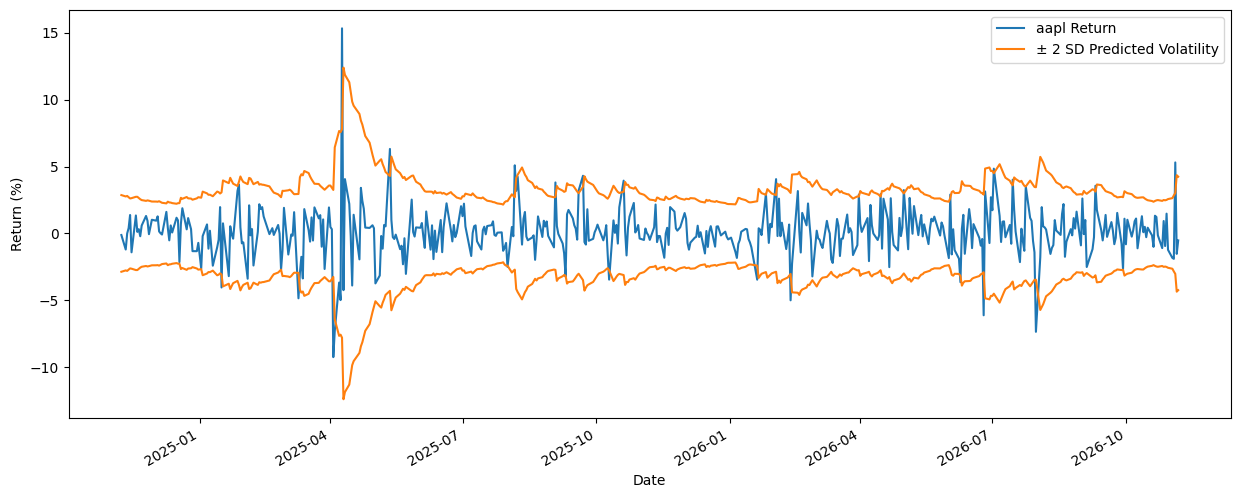

In [31]:
fig, ax = plt.subplots(figsize=(15, 6))

# Plot test-period returns
y_aapl.tail(test_size).plot(
    ax=ax, label="aapl Return"
)

# Plot +2 SD predicted volatility
(2 * y_test_wfv).plot(
    ax=ax, color="C1",
    label="± 2 SD Predicted Volatility"
)

# Plot -2 SD predicted volatility
(-2 * y_test_wfv).plot(ax=ax, color="C1")

ax.set_xlabel("Date")
ax.set_ylabel("Return (%)")
ax.legend()
plt.show()

In [32]:
prediction = model.forecast(
    horizon=5, reindex=False
).variance

print("prediction type:", type(prediction))
print("prediction shape:", prediction.shape)
prediction

prediction type: <class 'pandas.core.frame.DataFrame'>
prediction shape: (1, 5)


,h.1,h.2,h.3,h.4,h.5
date,,,,,
2024-11-07,2.052787,2.099134,2.143731,2.186644,2.227936


In [33]:
start = prediction.index[0] + pd.DateOffset(days=1)

# Generate business-day dates
pred_dates = pd.bdate_range(
    start=start, periods=prediction.shape[1]
)

# Convert to ISO 8601 strings
pred_index = [d.isoformat() for d in pred_dates]

print("pred_index type:", type(pred_index))
print("pred_index length:", len(pred_index))
pred_index

pred_index type: <class 'list'>
pred_index length: 5


['2024-11-08T00:00:00',
 '2024-11-11T00:00:00',
 '2024-11-12T00:00:00',
 '2024-11-13T00:00:00',
 '2024-11-14T00:00:00']

In [34]:
def clean_prediction(prediction):
    """Convert a variance forecast DataFrame to a dict.

    Parameters
    ----------
    prediction : pd.DataFrame
        Variance forecast from
        ``ARCHModelForecast.variance``.

    Returns
    -------
    dict
        Keys are ISO 8601 date strings (business days).
        Values are predicted volatility (std dev).
    """
    # 1. Compute start date (one day after the last training date)
    start = y_train.index[-1] + pd.DateOffset(days=1)

    # Generate business days matching the forecast horizon
    pred_dates = pd.bdate_range(start=start, periods=prediction.shape[1])

    # Convert dates to ISO 8601 strings
    pred_index = [d.isoformat() for d in pred_dates]

    # 2. Square root of variance = volatility
    data = prediction.values.flatten() ** 0.5

    pred_series = pd.Series(data, index=pred_index)
    return pred_series.to_dict()


# Test with a 10-day forecast
prediction_10 = model.forecast(
    horizon=10, reindex=False
).variance

prediction_formatted = clean_prediction(prediction_10)

print("Type:", type(prediction_formatted))
print("Number of entries:", len(prediction_formatted))
prediction_formatted

Type: <class 'dict'>
Number of entries: 10


{'2024-11-08T00:00:00': 1.432755113998195,
 '2024-11-11T00:00:00': 1.4488390015615016,
 '2024-11-12T00:00:00': 1.4641487040828376,
 '2024-11-13T00:00:00': 1.4787306175653323,
 '2024-11-14T00:00:00': 1.49262737757946,
 '2024-11-15T00:00:00': 1.5058782731826725,
 '2024-11-18T00:00:00': 1.5185196025351695,
 '2024-11-19T00:00:00': 1.530584980096878,
 '2024-11-20T00:00:00': 1.542105603355175,
 '2024-11-21T00:00:00': 1.5531104855234574}